<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🧩 Graph API 与控制流速查

**一句话定位**：LangGraph = `State`（共享数据）+ `Node`（改数据的函数）+ `Edge`（决定下一步）；编译后按 **super-step** 执行，每步末用 reducer 合并增量、写 checkpoint。
> 覆盖 module-1 骨架、module-2 schema、module-4 并行 / 子图 / map-reduce；本机 langgraph 1.2 实测。

</div>

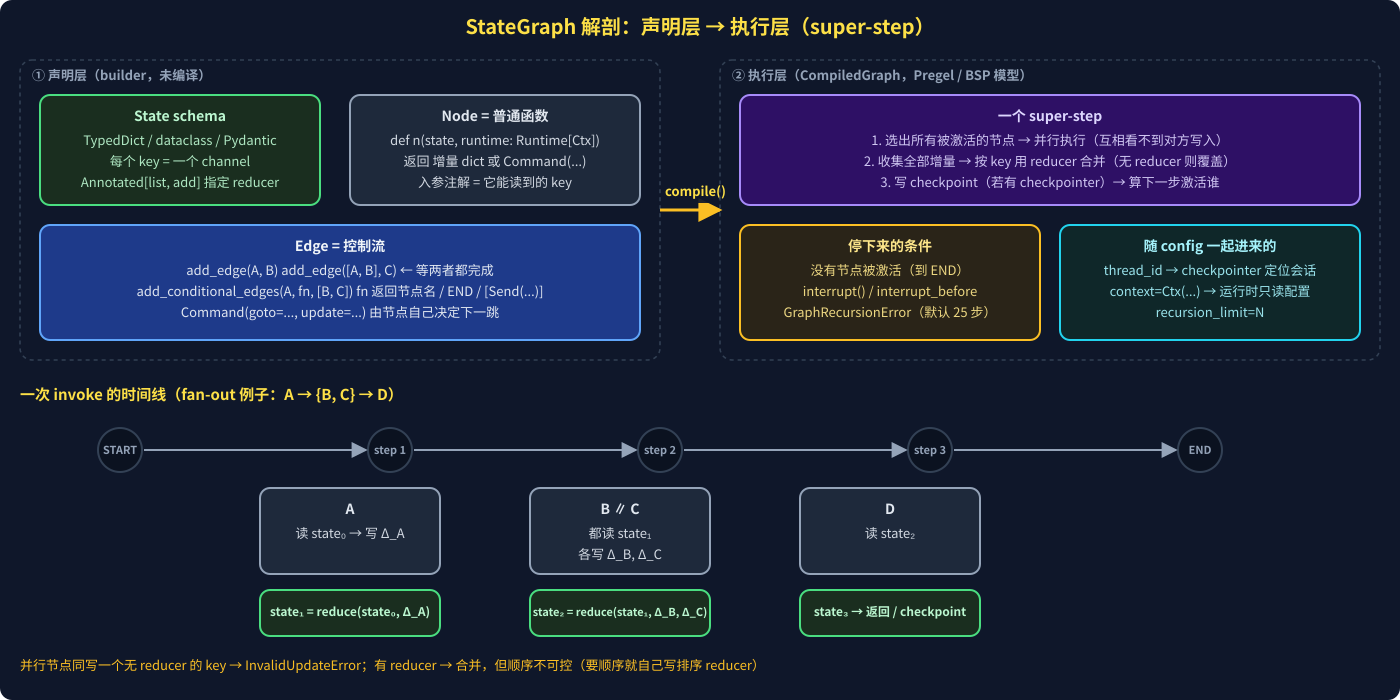

In [ ]:
from IPython.display import SVG
SVG(filename="assets/07_graph_anatomy.svg")

### 1️⃣ 最小骨架（所有 LangGraph 程序都长这样）

In [ ]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    text: str

def node_a(state: State):               # 入参 = 当前 state；返回 = 增量 dict
    return {"text": state["text"] + " A"}

builder = StateGraph(State)             # ① 声明 state
builder.add_node("a", node_a)           # ② 加节点（名字可省略：add_node(node_a) 用函数名）
builder.add_edge(START, "a")            # ③ 连边
builder.add_edge("a", END)
graph = builder.compile()               # ④ 编译 → 可 invoke / stream / get_graph()

graph.invoke({"text": "hi"})            # {'text': 'hi A'}

### 2️⃣ 节点能拿到什么、能返回什么

| 节点签名 | 注入内容 |
|---|---|
| `def n(state)` | 当前 state（按**入参注解**过滤 key） |
| `def n(state, config: RunnableConfig)` | `config["configurable"]`（thread_id、user_id…） |
| `def n(state, runtime: Runtime[Ctx])` | 🆕 `runtime.context`（只读配置）· `runtime.store` · `runtime.stream_writer` |
| `def n(state, store: BaseStore)` | 长期记忆 Store（老写法，仍可用） |

| 返回值 | 含义 |
|---|---|
| `{"key": 增量}` | 只写要改的 key，其余保持 |
| `{}` / `None` | 不改 state |
| `Command(update=…, goto=…)` | 改 state **并** 决定下一跳 |
| `[Send(...)]`（仅条件边函数） | 动态扇出 |

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**🆕 `context_schema` 取代 `config_schema`**（后者 1.0 弃用）：运行时**只读**参数（user_id、模型名、角色 prompt）放 context，不要塞进 state。

```python
@dataclass
class Ctx: user_id: str
builder = StateGraph(State, context_schema=Ctx)
graph.invoke(inputs, context=Ctx(user_id="u1"))      # 节点里 runtime.context.user_id
```

</div>

### 3️⃣ 边：4 种写法

In [ ]:
from typing import Literal
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, END
from langgraph.types import Send

class State(TypedDict):
    x: int

def route(state: State) -> Literal["b", "c", END]:
    return "b"

def fan_out(state: State):
    return [Send("w", {"x": 1})]

builder = StateGraph(State)
for name in ["a", "b", "c", "d", "w"]:
    builder.add_node(name, lambda state: {})

builder.add_edge("a", "b")                       # 普通边
builder.add_edge(["b", "c"], "d")                # fan-in：等 b、c 都完成才跑 d
builder.add_conditional_edges("a", route, ["b", "c"])   # 条件边：route(state) 返回 "b"/"c"/END
builder.add_conditional_edges("a", fan_out, ["w"])      # fan_out 返回 [Send("w", {...}), ...]

# 第三个参数（可能目标列表）不是必须，但给了才能画出正确的图、让 Studio 识别分支

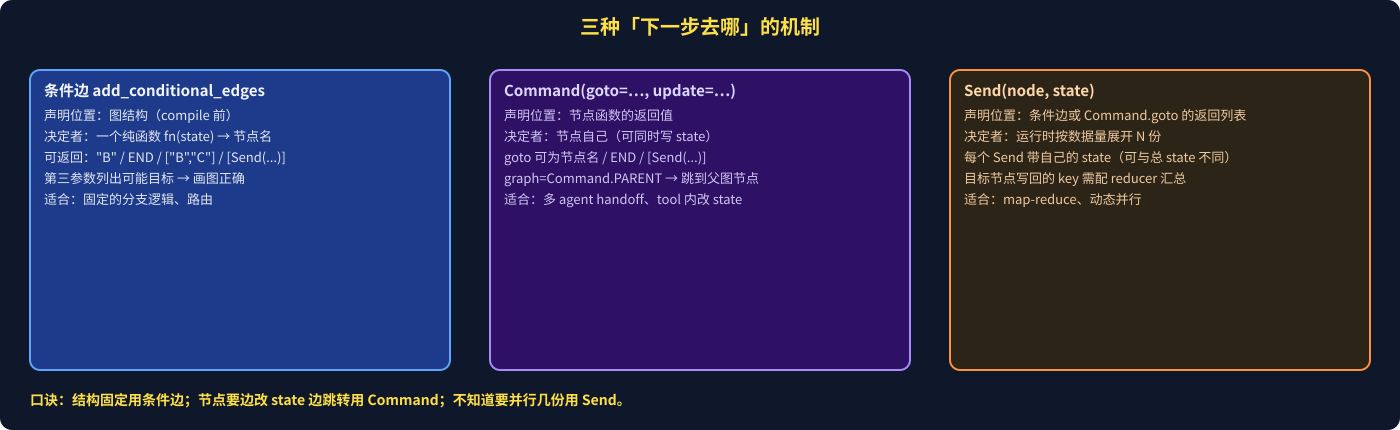

In [ ]:
from IPython.display import SVG
SVG(filename="assets/07_control_flow.svg")

In [ ]:
from typing import Literal
from langgraph.types import Command, Send
from langgraph.graph import END

# ① 条件边函数：纯路由
def route(state) -> Literal["b", "c", END]:
    return "b" if state["score"] > 0.5 else END

# ② Command：节点内决定下一跳 + 写 state（多 agent handoff 常用）
def agent_a(state) -> Command[Literal["agent_b", END]]:
    return Command(update={"notes": ["a done"]}, goto="agent_b")

# ③ Send：按数据展开 N 个并行任务（map）
def fan_out(state):
    return [Send("worker", {"item": x}) for x in state["items"]]   # worker 的 state 可与总 state 不同

def worker(state):          # state = {"item": ...}
    return {"results": [state["item"].upper()]}     # results 需 Annotated[list, operator.add] 才能汇总（reduce）

### 4️⃣ 并行（fan-out / fan-in）规则

| 规则 | 说明 |
|---|---|
| 同一 step 并行 | `a→b`、`a→c` 两条边 → b、c 同一 super-step 并行跑 |
| 同写一个 key | **必须有 reducer**，否则 `InvalidUpdateError: Can receive only one value per step` |
| 读到的 state | 并行节点都读上一步末的 state，**互相看不到**对方本步写入 |
| 合并顺序 | 由拓扑决定、**不可控**；要顺序 → 自定义排序 reducer，或先写临时字段再由 sink 节点整理 |
| 等待 | `add_edge(["b2","c"], "d")`：路径长短不一时，d 等**全部**前驱完成 |

### 5️⃣ 子图（Sub-graph）：两种接法

In [ ]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class ParentState(TypedDict):
    text: str
    out: str

class ChildState(TypedDict):
    msg: str
    reply: str

def reply_node(state: ChildState):
    return {"reply": state["msg"].upper()}

fa_builder = StateGraph(ChildState)
fa_builder.add_node("reply_node", reply_node)
fa_builder.add_edge(START, "reply_node")
fa_builder.add_edge("reply_node", END)
child_graph = fa_builder.compile()
parent = StateGraph(ParentState)

# 接法 A：直接当节点 —— 父子 state 有「重叠 key」时用；子图读写父图同名 key
parent.add_node("failure_analysis", fa_builder.compile())

# 接法 B：函数包裹 —— 父子 state 完全不同时用；手动转换输入/输出
def call_child(state: ParentState):
    out = child_graph.invoke({"msg": state["text"]})
    return {"out": out["reply"]}
parent.add_node("child", call_child)

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**并行子图的坑**：子图输出会**带出它 state 里的所有 key**（即使没改）。两个并行子图都带出 `cleaned_logs` → 等于并行写同一 key → 报错。解法：给子图 `output_schema=` 只声明真正要发布的 key，或给该 key 配 reducer。

画图看内部：`graph.get_graph(xray=1)`；流式看内部：`graph.stream(..., subgraphs=True)`。

</div>

### 6️⃣ Map-Reduce 模板（Send + reducer）

In [ ]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

def generate_topics(state):
    return {"subjects": ["cats", "dogs"]}

def generate_joke(state):
    return {"jokes": [f"a joke about {state['subject']}"]}

def best_joke(state):
    return {"best": state["jokes"][0]}

import operator
from typing import Annotated
from langgraph.types import Send

class Overall(TypedDict):
    topic: str
    subjects: list
    jokes: Annotated[list, operator.add]     # reduce：所有 worker 的结果在这里汇总
    best: str

def continue_to_jokes(state: Overall):       # map：按 subjects 数量展开
    return [Send("generate_joke", {"subject": s}) for s in state["subjects"]]

builder = StateGraph(Overall)
builder.add_node("generate_topics", generate_topics)
builder.add_node("generate_joke", generate_joke)      # 入参是 {"subject": ...}，返回 {"jokes": [...]}
builder.add_node("best_joke", best_joke)
builder.add_edge(START, "generate_topics")
builder.add_conditional_edges("generate_topics", continue_to_jokes, ["generate_joke"])
builder.add_edge("generate_joke", "best_joke")        # 所有 Send 分支完成后才进 best_joke
builder.add_edge("best_joke", END)

### 7️⃣ Schema 边界（详见 module-2 `003` 的两张图）

| 想要 | 写法 |
|---|---|
| 限制对外输入 / 输出 | `StateGraph(Overall, input_schema=In, output_schema=Out)` |
| 节点间私有中转 key | 在**下游节点入参注解**里声明 `PrivateState`，该 key 不进 `invoke` 结果 |
| 节点只看部分 key | 入参注解写子集 schema |

注意：过滤只作用于 `invoke` 返回值；`stream_mode="values"` 和 checkpoint 里仍能看到全部 channel。

### 🧭 排错速查

| 现象 | 原因 → 解法 |
|---|---|
| `InvalidUpdateError: only one value per step` | 并行写同 key 无 reducer → `Annotated[list, add]` |
| `GraphRecursionError` | 循环超 25 步（默认）→ `invoke(..., config={"recursion_limit": 100})`，或修终止条件 |
| 条件边返回的名字不存在 | compile 时报错 → 第三参数列全可能目标 |
| `Send` 目标节点 KeyError | Send 传的 state 缺 key → 节点只读 Send 给的 dict |
| 子图并行报重复写 | 带出未改 key → `output_schema` 收窄 |
| 节点返回了完整 state 却"没合并" | 返回值被当增量；有 reducer 的 list 会重复追加 → 只返回增量 |

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：`StateGraph(State) → add_node → add_edge/add_conditional_edges → compile()`；执行按 super-step，**并行节点读同一份旧 state、step 末 reducer 合并**；下一跳三选一——结构固定用条件边、节点自决用 `Command`、动态并行用 `Send`；子图靠重叠 key 或函数包裹通信。

</div>